In [6]:
import gzip
import html
import io
import os
import re
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lxml import etree
from tqdm.auto import tqdm

XML_GZ_PATH = "../data/raw/dblp.xml.gz"
CLEAN_OUT_PATH = "../data/processed/dblp_clean_2015_2025.parquet"
STATS_OUT_DIR = "../data/results"
FIGURES_DIR = "../figures"

os.makedirs(os.path.dirname(CLEAN_OUT_PATH), exist_ok=True)
os.makedirs(STATS_OUT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

START_YEAR = 2015
END_YEAR = 2025

In [7]:
DBLP_PUBLICATION_TAGS = {
    "article", "inproceedings", "proceedings", "book", 
    "incollection", "phdthesis", "mastersthesis", "www", "data"
}

ENTITY_PATTERN = re.compile(r"&([a-zA-Z]+);")
STANDARD_XML_ENTITIES = {"amp", "lt", "gt", "quot", "apos"}

def replace_html_entities(line: bytes) -> bytes:
    if b"&" not in line:
        return line
    text = line.decode("utf-8", errors="replace")
    def _sub(match):
        ent = match.group(1)
        if ent in STANDARD_XML_ENTITIES:
            return match.group(0)
        return html.unescape(match.group(0))
    return ENTITY_PATTERN.sub(_sub, text).encode("utf-8")

class DblpCleanStream:
    def __init__(self, gz_file, raw_file, pbar):
        self.gz_file = gz_file
        self.raw_file = raw_file
        self.pbar = pbar
        self.last_pos = 0
        self.buffer = io.BytesIO()

    def read(self, size=-1):
        while size < 0 or self.buffer.tell() < size:
            line = self.gz_file.readline()
            if not line:
                break
            if line.startswith(b"<!DOCTYPE"):
                continue
            self.buffer.write(replace_html_entities(line))

        current_pos = self.raw_file.tell()
        if current_pos > self.last_pos:
            self.pbar.update(current_pos - self.last_pos)
            self.last_pos = current_pos

        data = self.buffer.getvalue()
        self.buffer = io.BytesIO()
        return data

# full scan untuk menghitung distribusi seluruh jenis publikasi
pub_type_counts = Counter()
sample_structure = None
total_gz_bytes = os.path.getsize(XML_GZ_PATH)

with open(XML_GZ_PATH, "rb") as raw_f, tqdm(
    total=total_gz_bytes, unit="B", unit_scale=True, unit_divisor=1024
) as pbar:
    with gzip.open(raw_f, "rb") as gz_f:
        clean_stream = DblpCleanStream(gz_f, raw_f, pbar)
        context = etree.iterparse(clean_stream, events=("end",), recover=True)
        for _, elem in context:
            if elem.tag in DBLP_PUBLICATION_TAGS:
                pub_type_counts[elem.tag] += 1
                if elem.tag == "inproceedings" and sample_structure is None:
                    sample_structure = {
                        "tag": elem.tag,
                        "attributes": dict(elem.attrib),
                        "child_tags": [child.tag for child in elem]
                    }
                elem.clear()
                while elem.getprevious() is not None:
                    del elem.getparent()[0]

df_pub_types = pd.DataFrame(pub_type_counts.items(), columns=["publication_type", "total_records"])
df_pub_types = df_pub_types.sort_values("total_records", ascending=False).reset_index(drop=True)
print("total record publikasi di DBLP:", f"{df_pub_types['total_records'].sum():,}")
display(df_pub_types)
print("\nexample struktur tag <inproceedings>:")
print(sample_structure)

100%|██████████| 1.04G/1.04G [02:55<00:00, 6.39MB/s]

total record publikasi di DBLP: 13,115,316


,publication_type,total_records
0,article,4521786
1,www,4243328
2,inproceedings,4001570
3,phdthesis,158395
4,incollection,71264
5,proceedings,65862
6,data,31430
7,book,21654
8,mastersthesis,27



example struktur tag <inproceedings>:
{'tag': 'inproceedings', 'attributes': {'mdate': '2022-10-02', 'key': 'series/sapere/Freed13'}, 'child_tags': ['author', 'title', 'pages', 'year', 'booktitle', 'ee', 'crossref', 'url']}


In [8]:
def normalize_author(name: str) -> str:
    cleaned = re.sub(r"\s+", " ", name.strip())
    return cleaned

def normalize_venue(key: str, booktitle: str) -> tuple[str, str]:
    venue_code = ""
    if key:
        parts = key.split("/")
        if len(parts) >= 2 and parts[0] == "conf":
            venue_code = parts[1].lower().strip()
    venue_name = re.sub(r"\s+", " ", booktitle.strip()) if booktitle else venue_code.upper()
    return venue_code, venue_name

# counter untuk audit log setiap tahap preprocessing
audit_log = {
    "1_total_inproceedings_all_years": 0,
    "2_filtered_year_2015_2025": 0,
    "3_dropped_missing_values": 0,
    "4_valid_before_dedup": 0,
    "5_dropped_duplicates": 0,
    "6_final_clean_records": 0,
}

raw_records = []

with open(XML_GZ_PATH, "rb") as raw_f, tqdm(
    total=total_gz_bytes, unit="B", unit_scale=True, unit_divisor=1024
) as pbar:
    with gzip.open(raw_f, "rb") as gz_f:
        clean_stream = DblpCleanStream(gz_f, raw_f, pbar)
        context = etree.iterparse(clean_stream, events=("end",), tag="inproceedings", recover=True)
        
        for _, elem in context:
            audit_log["1_total_inproceedings_all_years"] += 1
            
            # atribut tahun (2015 - 2025)
            year_text = elem.findtext("year")
            if year_text and year_text.strip().isdigit():
                year_val = int(year_text.strip())
                if START_YEAR <= year_val <= END_YEAR:
                    audit_log["2_filtered_year_2015_2025"] += 1
                    
                    key = elem.get("key", "").strip()
                    booktitle = elem.findtext("booktitle", "")
                    venue_code, venue_name = normalize_venue(key, booktitle)
                    
                    title_elem = elem.find("title")
                    title = re.sub(r"\s+", " ", "".join(title_elem.itertext())).strip() if title_elem is not None else ""
                    
                    # normalisasi author, pertahankan urutan, hindari duplikat author dalam 1 paper
                    seen_authors = set()
                    authors = []
                    for a in elem.findall("author"):
                        if a.text and a.text.strip():
                            norm_a = normalize_author(a.text)
                            if norm_a not in seen_authors:
                                seen_authors.add(norm_a)
                                authors.append(norm_a)
                    
                    # handle missing values
                    if not venue_code or not title or len(authors) == 0:
                        audit_log["3_dropped_missing_values"] += 1
                    else:
                        raw_records.append({
                            "paper_key": key,
                            "title": title,
                            "year": year_val,
                            "venue_code": venue_code,
                            "venue_name": venue_name,
                            "authors": authors
                        })
            
            elem.clear()
            while elem.getprevious() is not None:
                del elem.getparent()[0]

df_clean = pd.DataFrame(raw_records)
audit_log["4_valid_before_dedup"] = len(df_clean)

# remove data duplikat (berdasarkan paper_key dan kombinasi title_lower, year, venue_code)
df_clean["title_lower"] = df_clean["title"].str.lower()
df_clean = df_clean.drop_duplicates(subset=["paper_key"], keep="first")
df_clean = df_clean.drop_duplicates(subset=["title_lower", "year", "venue_code"], keep="first")
df_clean = df_clean.drop(columns=["title_lower"]).reset_index(drop=True)

audit_log["5_dropped_duplicates"] = audit_log["4_valid_before_dedup"] - len(df_clean)
audit_log["6_final_clean_records"] = len(df_clean)

df_audit = pd.DataFrame(list(audit_log.items()), columns=["Tahap_Preprocessing", "Jumlah_Record"])
display(df_audit)

100%|██████████| 1.04G/1.04G [03:44<00:00, 5.00MB/s]


,Tahap_Preprocessing,Jumlah_Record
0,1_total_inproceedings_all_years,4001570
1,2_filtered_year_2015_2025,2004103
2,3_dropped_missing_values,5416
3,4_valid_before_dedup,1998687
4,5_dropped_duplicates,1542
5,6_final_clean_records,1997145


In [9]:
# save dataset bersih ke format parquet
df_clean.to_parquet(CLEAN_OUT_PATH, index=False)
print(f"Dataset bersih berhasil disimpan ke: {CLEAN_OUT_PATH}")

# statistik akhir
total_publikasi = len(df_clean)
all_authors_exploded = df_clean["authors"].explode()
total_author_unik = all_authors_exploded.nunique()
total_venue_unik = df_clean["venue_code"].nunique()

print(f"1. Total Publikasi        : {total_publikasi:,}")
print(f"2. Total Author Unik      : {total_author_unik:,}")
print(f"3. Total Conference Unik  : {total_venue_unik:,}")
print(f"4. Rata-rata Author/Paper : {len(all_authors_exploded) / total_publikasi:.2f}")

# distribusi publikasi berdasarkan tahun
dist_tahun = (
    df_clean.groupby("year")
    .agg(
        jumlah_publikasi=("paper_key", "count"),
        jumlah_venue_aktif=("venue_code", "nunique")
    )
    .reset_index()
)
dist_tahun["persentase (%)"] = (dist_tahun["jumlah_publikasi"] / total_publikasi * 100).round(2)

# distribusi publikasi berdasarkan conference
dist_venue = (
    df_clean.groupby("venue_code")
    .agg(
        jumlah_publikasi=("paper_key", "count"),
        contoh_nama_venue=("venue_name", "first")
    )
    .sort_values("jumlah_publikasi", ascending=False)
    .reset_index()
)
dist_venue["persentase (%)"] = (dist_venue["jumlah_publikasi"] / total_publikasi * 100).round(2)

# tabel statistik
df_audit.to_csv(f"{STATS_OUT_DIR}/task1_preprocessing_audit.csv", index=False)
dist_tahun.to_csv(f"{STATS_OUT_DIR}/task1_distribusi_tahun.csv", index=False)
dist_venue.to_csv(f"{STATS_OUT_DIR}/task1_distribusi_venue.csv", index=False)

print("\ndistribusi publikasi per tahun")
display(dist_tahun)

print("\ntop 15 distribusi publikasi per conference")
display(dist_venue.head(15))

Dataset bersih berhasil disimpan ke: ../data/processed/dblp_clean_2015_2025.parquet
1. Total Publikasi        : 1,997,145
2. Total Author Unik      : 1,821,562
3. Total Conference Unik  : 4,372
4. Rata-rata Author/Paper : 3.94

distribusi publikasi per tahun


,year,jumlah_publikasi,jumlah_venue_aktif,persentase (%)
0,2015,160800,1975,8.05
1,2016,161650,2016,8.09
2,2017,167767,2066,8.40
3,2018,176309,2158,8.83
4,2019,188436,2241,9.44
5,2020,171772,2045,8.60
6,2021,178166,2217,8.92
7,2022,178074,2275,8.92
8,2023,201387,2356,10.08
9,2024,213301,2273,10.68



top 15 distribusi publikasi per conference


,venue_code,jumlah_publikasi,contoh_nama_venue,persentase (%)
0,nips,25455,NIPS,1.27
1,cvpr,22751,CVPR,1.14
2,icassp,21606,ICASSP,1.08
3,hci,19912,HCI (6),1.00
4,igarss,19685,IGARSS,0.99
5,aaai,19274,AAAI,0.97
6,chi,14832,CHI,0.74
7,emnlp,14813,EMNLP (Findings),0.74
8,embc,14676,EMBC,0.73
9,icc,14329,ICC,0.72


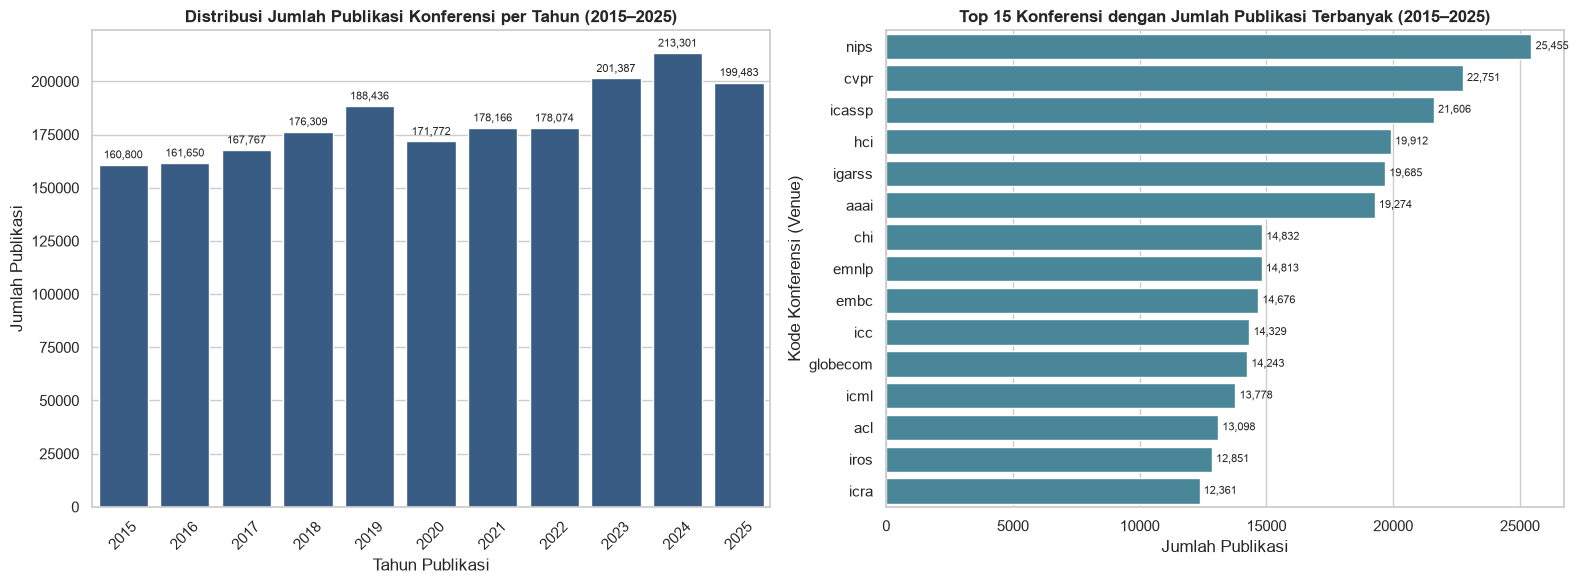

In [10]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=dist_tahun, x="year", y="jumlah_publikasi", color="#2b5c8f", ax=axes[0])
axes[0].set_title("Distribusi Jumlah Publikasi Konferensi per Tahun (2015–2025)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Tahun Publikasi")
axes[0].set_ylabel("Jumlah Publikasi")
axes[0].tick_params(axis="x", rotation=45)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="{:,.0f}", fontsize=8, padding=3)

top15_venue = dist_venue.head(15)
sns.barplot(data=top15_venue, y="venue_code", x="jumlah_publikasi", color="#3b8ea5", ax=axes[1])
axes[1].set_title("Top 15 Konferensi dengan Jumlah Publikasi Terbanyak (2015–2025)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Jumlah Publikasi")
axes[1].set_ylabel("Kode Konferensi (Venue)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="{:,.0f}", fontsize=8, padding=3)

plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/task1_distribusi_dataset.png", dpi=300, bbox_inches="tight")
plt.show()